In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv(r"C:\Users\roypr\Downloads\data_science_job.csv")

In [9]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [10]:
df.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [11]:
df.shape

(19158, 13)

In [13]:
cols = [var for var in df.columns if df[var].isnull().mean()<0.05 and df[var].isnull().mean()>0]
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [14]:
df[cols].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
16534,0.920,Full time course,Graduate,5.0,43.0
4736,0.698,no_enrollment,Graduate,3.0,121.0
9788,0.624,no_enrollment,Graduate,6.0,55.0
11747,0.884,no_enrollment,Graduate,6.0,28.0
4795,0.920,Full time course,High School,5.0,30.0


In [15]:
len(df[cols].dropna())/len(df)

0.8968577095730244

In [16]:
new_df = df[cols].dropna()
df.shape,new_df.shape

((19158, 13), (17182, 5))

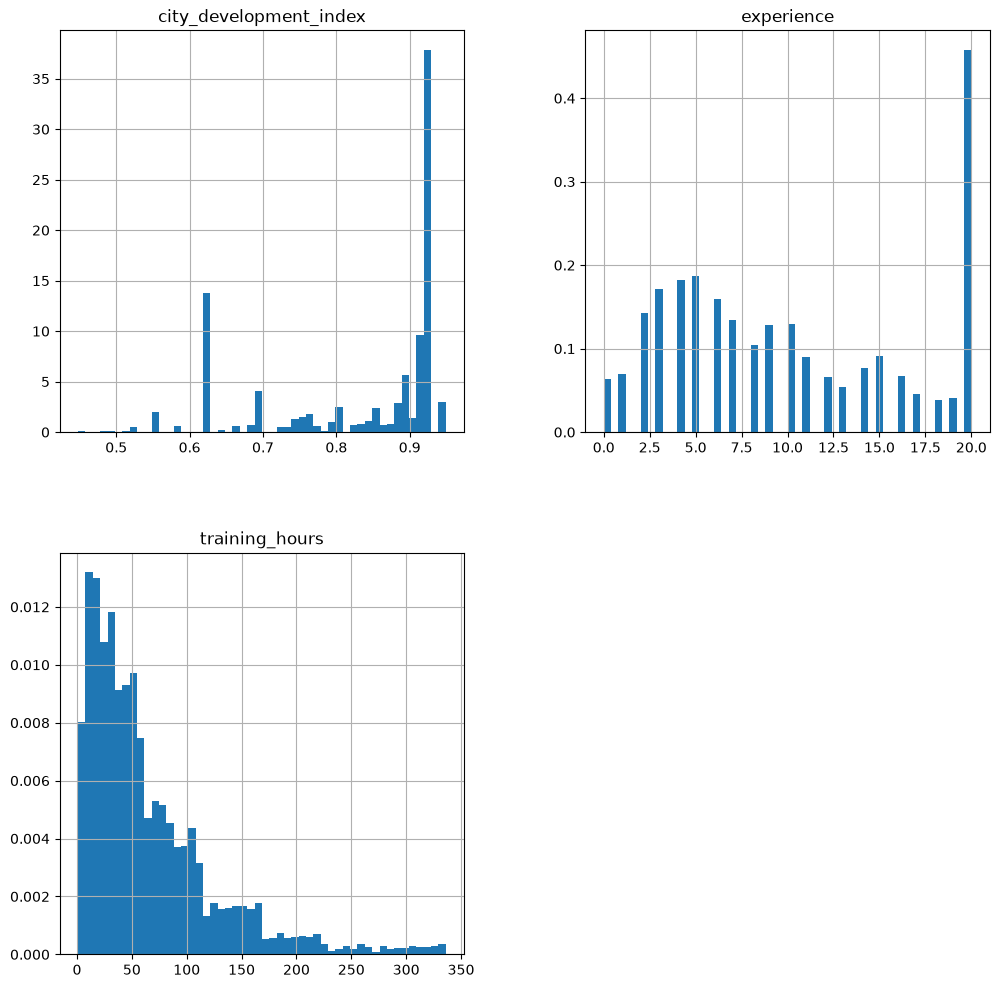

In [18]:
new_df.hist(bins = 50,density = True,figsize=(12,12))
plt.show()

<Axes: >

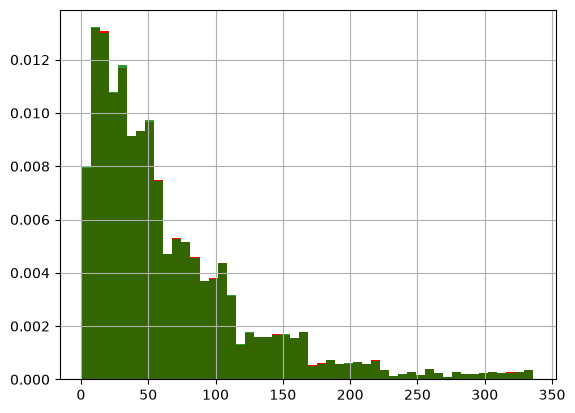

In [19]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['training_hours'].hist(bins=50, ax=ax, density=True, color='red')

# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
new_df['training_hours'].hist(bins=50, ax=ax, color='green', density=True, alpha=0.8)

<Axes: >

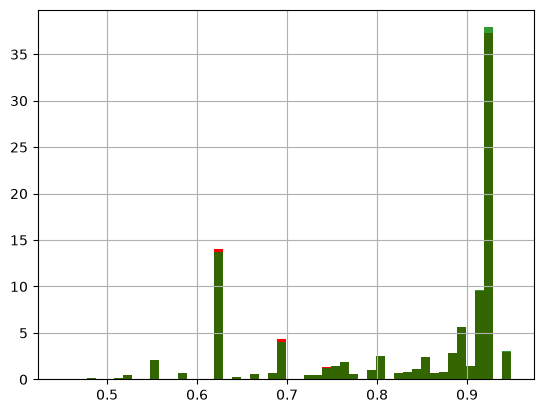

In [20]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['city_development_index'].hist(bins=50, ax=ax, density=True, color='red')

# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
new_df['city_development_index'].hist(bins=50, ax=ax, color='green', density=True, alpha=0.8)

In [22]:
temp = pd.concat([
    #percentage of obseravtions per category,orginal data
    df['enrolled_university'].value_counts()/len(new_df),
    
    #percentage of observations per category,cca data
    new_df['enrolled_university'].value_counts()/len(new_df)
],
axis = 1)

#add column names
temp.columns = ['orginal','cca']

temp

,orginal,cca
enrolled_university,,
no_enrollment,0.804156,0.735188
Full time course,0.218659,0.200733
Part time course,0.069724,0.064079


In [23]:
temp = pd.concat([
    #percentage of obseravtions per category,orginal data
    df['education_level'].value_counts()/len(new_df),
    
    #percentage of observations per category,cca data
    new_df['education_level'].value_counts()/len(new_df)
],
axis = 1)

#add column names
temp.columns = ['orginal','cca']

temp

,orginal,cca
education_level,,
Graduate,0.675009,0.619835
Masters,0.253812,0.234082
High School,0.117390,0.107380
Phd,0.024095,0.022116
Primary School,0.017926,0.016587
